<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


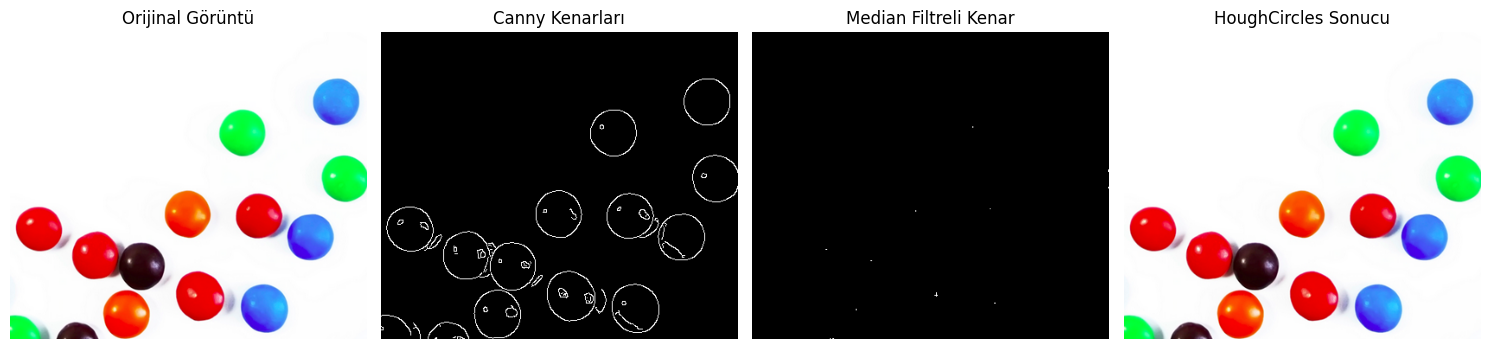

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/smarties.png'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

median_edges = cv2.medianBlur(edges, 5)

img_circles = img.copy()
circles = cv2.HoughCircles(
    median_edges,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=25,
    param1=100,
    param2=22,
    minRadius=10,
    maxRadius=80
)

if circles is not None:
    circles_rounded = np.uint16(np.around(circles))
    for x, y, r in circles_rounded[0, :]:
        cv2.circle(img_circles, (x, y), r, (0, 255, 255), 2)
        cv2.circle(img_circles, (x, y), 2, (255, 0, 255), 3)

plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(edges, cmap='gray')
plt.title('Canny Kenarları')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(median_edges, cmap='gray')
plt.title('Median Filtreli Kenar')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
plt.title('HoughCircles Sonucu')
plt.axis('off')

plt.tight_layout()
plt.show()